# The published predictors on their own validation tables, reproduced and scored on two statistics

**Question:** How good are the published predictors on their own hold-out tables?

**Level 3: State of the art** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast, 02-classical-prediction/02-the-rock-factor · Reading time: about 30 minutes

## Objectives

The state of the art for this problem is two published papers that each validate three predictors on a small hold-out table and print their predictions next to the measurements. This notebook takes those printed columns as the reference, scores them with the engine's scorer, recomputes the published regression from its own equations, and puts the classical column beside the engine's classical predictor. The question is how good the published predictors really are on their own tables, which also means how much a table of 12 blasts can say.

By the end you will have:

- scored the printed classical, regression and network columns on the 12-blast table with two named statistics, and seen that they give different answers to the same column;
- put a 95 percent interval on each score, and seen how wide it is for 12 blasts;
- recomputed the published regression from its equations on both validation sets and compared it with the column the papers printed;
- measured how much the one blast that is also a training row changes the picture.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, sets the plotting style and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, the pinned versions, the plotting style and one helper that renders a table
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 13-blast validation set and the printed predictions of the 2010 paper | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | `bf.load_holdout(protocol="2010")` inside the `blastfrag` wheel |
| The 12-blast validation set and the printed predictions of the 2012 paper (Kuz-Ram, regression, network) | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | numeric facts reused with citation; the article never ships | `bf.load_holdout(protocol="2012")` and `protocol="union"` |
| The equations of the published regression, and the training corpus | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation | `bf.PublishedRegression` and `bf.load_training_corpus()` inside the wheel |

Each validation blast carries, in its metadata, the value each paper printed for it, so a printed column is data that the notebook scores like any other prediction. No file under `data/` is read.

## Method

Scoring a prediction column needs two statistics, because this literature uses one name for two different quantities.

- The **Pearson r2** is the square of the correlation between predicted and measured sizes, which any straight line of any slope and offset can satisfy.
- The **variance explained about the identity line** is `1 - SS_res / SS_tot`, with the residuals taken against `predicted = measured` and not against a fitted line, so it penalises bias and a wrong slope.

The engine's `bf.score` returns both under their own names (`pearson_r2`, `r2_identity`), and every figure of the product says which one it shows. A printed value goes through exactly the same scorer as the engine's own predictors once it is wrapped in a `Prediction`. Because the table has only 12 blasts, each score also gets a 95 percent interval from `bf.bootstrap_interval`, which resamples the blasts with replacement 2000 times and takes the 2.5th and 97.5th percentiles of the resampled scores. Treating the 12 blasts as independent is generous, since three sites contribute two blasts each, so the intervals are if anything optimistic.

### Step 1: the printed columns on the 12-blast table

The cell loads the 2012 validation set, wraps each printed column (Kuz-Ram, regression, network) in `Prediction` objects, and scores them with `bf.score`, which prints both statistics. The null model, which predicts the training mean for every blast and uses no input at all, is scored on the same rows as the reference that any predictor must beat.

In [2]:
# Score each printed column with the engine's scorer, the training mean as reference
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="2012")
columns = {"Kuz-Ram (kuzram_2012)": "kuzram_2012", "regression (regression_2012)": "regression_2012",
           "network (nn_mean_2012)": "nn_mean_2012"}
printed = {}
for column in columns.values():
    values = [b.meta["published"][column] for b in holdout]
    printed[column] = [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=v) for b, v in zip(holdout, values)]
null = bf.null_model_score(holdout, training_mean_m=bf.training_mean(train))
rows = []
for label, column in columns.items():
    s = bf.score(holdout, printed[column], method=column)
    rows.append((label, f"{s.pearson_r2:.4f}", f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}", f"{s.bias_m:+.4f}"))
rows.append(("null (training mean)", "-", f"{null.r2_identity:.4f}", f"{null.rmse_m:.4f}",
             f"{null.bias_m:+.4f}"))
header = ["printed column", "Pearson r2", "r2 about identity",
          "RMSE (m)", "bias (m)"]
show_table(header, rows)

| printed column | Pearson r2 | r2 about identity | RMSE (m) | bias (m) |
|:---|---:|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.5698 | 0.2318 | 0.1279 | +0.0033 |
| regression (regression_2012) | 0.8197 | 0.7082 | 0.0788 | -0.0483 |
| network (nn_mean_2012) | 0.9372 | 0.9096 | 0.0439 | -0.0242 |
| null (training mean) | - | -0.0093 | 0.1466 | -0.0141 |

The same column has two scores. The printed Kuz-Ram column has a Pearson r2 of 0.5698 but a variance explained about the identity line of only 0.2318: its sizes are correlated with the measurements without being close to them. The regression reaches 0.7082 on the identity statistic (0.8197 as a correlation) and the network 0.9096 (0.9372). The null model scores -0.0093, so all three predictors beat a constant, the classical one narrowly: its RMSE is 0.1279 m against 0.1466 m. A table reported only with the correlation would rank the classical column higher than it deserves.

A score on 12 blasts is a point estimate with a wide shadow. The cell resamples the 12 blasts with replacement 2000 times for each column, recomputes the variance explained about the identity line on every resample, and reports the 2.5th and 97.5th percentiles. The width of the interval is the honest size of what the table can claim.

In [3]:
# A 95 percent interval for each variance explained, resampling the 12 blasts 2000 times
rows = []
for label, column in columns.items():
    point, low, high = bf.bootstrap_interval(holdout, printed[column], "r2_identity", n_boot=2000, unit="blast", seed=0)
    rows.append((label, f"{point:.3f}", f"{low:.3f} to {high:.3f}", f"{high - low:.2f}"))
header = ["printed column", "r2 about identity", "interval 95 %",
          "interval width"]
show_table(header, rows)

| printed column | r2 about identity | interval 95 % | interval width |
|:---|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.232 | -1.811 to 0.857 | 2.67 |
| regression (regression_2012) | 0.708 | -0.022 to 0.874 | 0.90 |
| network (nn_mean_2012) | 0.910 | 0.648 to 0.974 | 0.33 |

The intervals are wide. The Kuz-Ram column, 0.232, spans -1.811 to 0.857, a width of 2.67; the regression, 0.708, spans -0.022 to 0.874; the network, 0.910, spans 0.648 to 0.974. Only the network's interval stays clear of zero. So the ranking of the three columns is visible in the point scores, but the regression's interval lies almost entirely inside the classical column's: on 12 blasts the table cannot separate them. The next cell shows the three columns against the measurements.

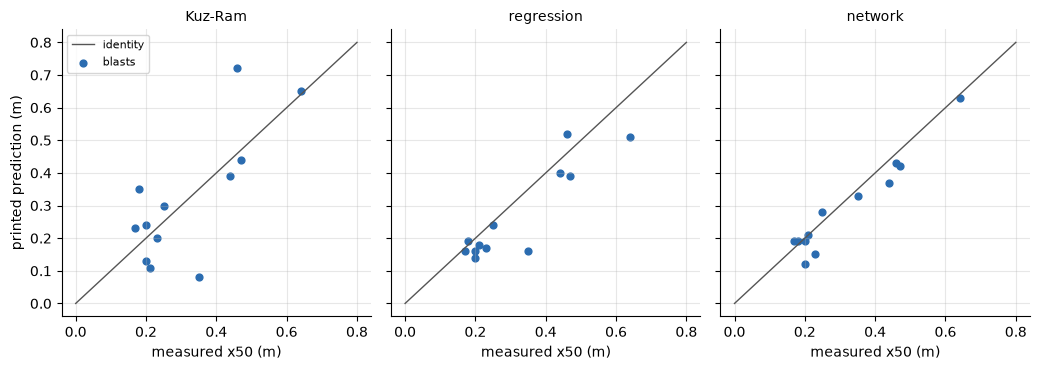

In [4]:
# Printed predictions against the measurements for the three published predictors, with the identity line
measured = np.array([b.x50_m for b in holdout])
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharex=True, sharey=True)
for ax, (label, column) in zip(axes, columns.items()):
    values = np.array([p.x50_m for p in printed[column]])
    ax.plot([0, 0.8], [0, 0.8], color="#555", lw=1, label="identity")
    ax.scatter(measured, values, s=24, color="#2b6cb0", label="blasts")
    ax.set_title(label.split(" (")[0], fontsize=10)
    ax.set_xlabel("measured x50 (m)")
axes[0].set_ylabel("printed prediction (m)")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Each panel plots a printed column against the measured size, with the identity line. The network's points hug the line; the regression's follow it with a low bias and two large misses; the Kuz-Ram points scatter widely around it, with one blast predicted at about 0.72 m that measured 0.46 m and one predicted at about 0.08 m that measured 0.35 m. The panels show where the scores of the table come from, blast by blast. They do not show how the predictors behave at a mine they have not seen: the 12 blasts come from sites that are also in the training table.

## State of the art

Three papers define what is already known, and each validates on a small fixed table.

- **Hudaverdi, Kulatilake and Kuzu 2010** (https://doi.org/10.1002/nag.957) fit a regression to the 97 blasts, route each blast to one of two rock-stiffness groups with a discriminant, and validate on a 13-blast hold-out against a Kuz-Ram column.
- **Kulatilake, Hudaverdi and Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) add a back-propagation network (seven inputs, one hidden layer, Levenberg-Marquardt, one network per group) and validate the three predictors on a 12-blast hold-out. The SDD records that the published parity fit of the Kuz-Ram column on that hold-out is 0.5697, which is the Pearson r2 that Step 1 reproduces to 0.5698.
- **Amoako, Jha and Zhong 2022** (https://doi.org/10.3390/mining2020013) reprint the classical equation and its corrections, which the engine's classical predictor follows.

Both validations report a table of predictions on a small fixed hold-out, with the correlation as the headline statistic. The cells below run the published regression and the engine's classical predictor on those same blasts and compare them with the printed columns.

### Step 2: the published regression, recomputed

The regression of the 2010 paper is two power laws, one per rock-stiffness group, with a discriminant that routes each blast. The engine's `PublishedRegression` applies the equations as printed. The cell applies it to the blasts of each validation set and scores the result against the column the papers printed for the same blasts, with the blast-resampling interval of each. If the printed table and the printed equations agree, the two columns should coincide.

In [5]:
# The published regression recomputed from its equations against the column printed, on both validation sets
union = bf.load_holdout(protocol="union")
regression = bf.PublishedRegression()
comparison = {}
for year in ("2010", "2012"):
    column = f"regression_{year}"
    rows_year = [b for b in union if b.meta["published"][column] is not None]
    values = [b.meta["published"][column] for b in rows_year]
    as_printed = [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=v) for b, v in zip(rows_year, values)]
    comparison[year] = (rows_year, as_printed, regression.predict(rows_year))
rows = []
for year, (rows_year, as_printed, recomputed) in comparison.items():
    first = bf.bootstrap_interval(rows_year, as_printed, "r2_identity", n_boot=2000, unit="blast", seed=0)
    second = bf.bootstrap_interval(rows_year, recomputed, "r2_identity", n_boot=2000, unit="blast", seed=0)
    rows.append((year, len(rows_year), f"{first[0]:.4f}", f"{second[0]:.4f}", f"{second[0] - first[0]:+.4f}",
                 f"{first[1]:.2f} to {first[2]:.2f}", f"{second[1]:.2f} to {second[2]:.2f}"))
header = ["set", "n", "printed", "recomputed", "gain",
          "interval, printed", "interval, recomputed"]
show_table(header, rows)

| set | n | printed | recomputed | gain | interval, printed | interval, recomputed |
|:---|---:|---:|---:|---:|---:|---:|
| 2010 | 13 | 0.7467 | 0.8537 | +0.1070 | -0.18 to 0.89 | 0.61 to 0.91 |
| 2012 | 12 | 0.7082 | 0.8272 | +0.1190 | -0.02 to 0.87 | 0.65 to 0.88 |

They do not coincide. On the 2010 set of 13 blasts, the recomputed regression explains 0.8537 of the variance against 0.7467 for the printed column, a gain of 0.1070; on the 2012 set of 12 blasts, 0.8272 against 0.7082, a gain of 0.1190. The table the papers printed is therefore not what their own equations produce, and the equations do better. The intervals, however, overlap: -0.18 to 0.89 against 0.61 to 0.91 in 2010, and -0.02 to 0.87 against 0.65 to 0.88 in 2012, so on this many blasts the gain is smaller than the uncertainty of either score.

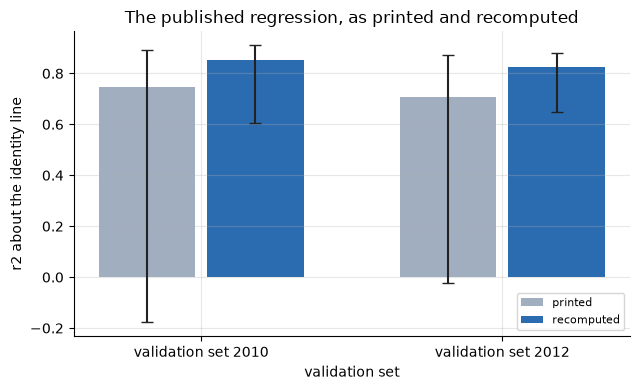

In [6]:
# Variance explained about the identity line, printed against recomputed, with the 95 percent intervals
fig, ax = plt.subplots(figsize=(6.5, 4))
for offset, (kind, color) in zip((-0.18, 0.18), (("printed", "#a0aec0"), ("recomputed", "#2b6cb0"))):
    for position, (year, (rows_year, as_printed, recomputed)) in enumerate(comparison.items()):
        predictions = as_printed if offset < 0 else recomputed
        interval = bf.bootstrap_interval(rows_year, predictions, "r2_identity", n_boot=2000, unit="blast", seed=0)
        point, low, high = interval
        ax.bar(position + offset, point, width=0.32, color=color, label=kind if position == 0 else None)
        ax.errorbar(position + offset, point, yerr=[[point - low], [high - point]], color="#222", capsize=4)
ax.set_xticks(range(len(comparison)), [f"validation set {year}" for year in comparison])
ax.set_xlabel("validation set")
ax.set_ylabel("r2 about the identity line")
ax.set_title("The published regression, as printed and recomputed")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Each pair of bars is one validation set: grey for the column as printed, blue for the regression recomputed from the equations, with a black whisker for the 95 percent interval. The blue bars are higher in both sets and their whiskers are much shorter, which says that the recomputed predictions are more consistent across resamples; the grey whiskers reach below zero. The figure shows a difference between a printed table and printed equations. It does not show which of the two carries a slip: that would need the papers' own working, which the corpus does not hold.

### Step 3: the classical column and the engine's classical predictor

The printed Kuz-Ram column and the engine's `Kuznetsov` predictor, which uses the per-site rock factor recovered from that very column (previous notebook), should nearly coincide; the difference is the rounding of the printed values to two decimals. The cell lists the two side by side for the 12 blasts with the measured size and the gap.

In [7]:
# The printed Kuz-Ram column beside the engine's classical predictor, blast by blast
classical = bf.Kuznetsov().predict(holdout)
rows = []
for blast, prediction in zip(holdout, classical):
    shown = blast.meta["published"]["kuzram_2012"]
    gap = abs(prediction.x50_m - shown)
    sizes = (f"{blast.x50_m:.2f}", f"{shown:.2f}", f"{prediction.x50_m:.3f}", f"{gap:.3f}")
    rows.append((blast.blast_id, blast.site, *sizes))
header = ["blast", "site", "measured (m)", "printed (m)", "engine (m)",
          "gap (m)"]
show_table(header, rows, left=2)
print("largest gap, printed column against engine (m):", max(float(r[5]) for r in rows))

| blast | site | measured (m) | printed (m) | engine (m) | gap (m) |
|:---|:---|---:|---:|---:|---:|
| En13 | Enusa | 0.47 | 0.44 | 0.440 | 0.000 |
| Ru7 | Reocin-UG | 0.64 | 0.65 | 0.650 | 0.000 |
| Mg8 | Murgul | 0.44 | 0.39 | 0.387 | 0.003 |
| Mg9 | Murgul | 0.25 | 0.30 | 0.302 | 0.002 |
| Rc1 | Reocin | 0.46 | 0.72 | 0.720 | 0.000 |
| Mr12 | Mrica | 0.20 | 0.24 | 0.240 | 0.000 |
| Db10 | Dongri-Buzurg | 0.35 | 0.08 | 0.080 | 0.000 |
| Sm8 | Soma | 0.18 | 0.35 | 0.350 | 0.000 |
| Oz8 | Ozmert | 0.23 | 0.20 | 0.198 | 0.002 |
| Oz9 | Ozmert | 0.17 | 0.23 | 0.232 | 0.002 |
| Ad23 | Akdaglar | 0.21 | 0.11 | 0.108 | 0.002 |
| Ad24 | Akdaglar | 0.20 | 0.13 | 0.132 | 0.002 |

largest gap, printed column against engine (m): 0.003


The largest gap between the printed column and the engine is 0.003 m, below the rounding of the printed values, so the engine reproduces the published classical column from the published equation and the recovered factors. That agreement is a consistency check of the geometry reconstruction and of the factors, not independent evidence of skill: the factors were recovered from this same column. The two columns also share their misses, for instance Rc1, printed 0.72 m against 0.46 m measured, and Db10, printed 0.08 m against 0.35 m. The table says the engine's classical predictor is the published one; it does not say it is accurate.

### Step 4: the blast that is also a training row

One of the 12 validation blasts is also a row of the training table, which a hold-out is supposed to keep apart; the engine flags it in the blast's metadata. The cell scores the three printed columns on the 12 blasts and on the 11 that remain without it, and prints the change in the variance explained about the identity line.

In [8]:
# Score the three printed columns with and without the blast that is also a training row
leaked = [b.blast_id for b in holdout if b.meta["in_training_table"]]
keep = [i for i, b in enumerate(holdout) if not b.meta["in_training_table"]]
clean = [holdout[i] for i in keep]
effect = {}
for label, column in columns.items():
    full = bf.score(holdout, printed[column]).r2_identity
    without = bf.score(clean, [printed[column][i] for i in keep]).r2_identity
    effect[label] = (full, without)
rows = [(label, f"{full:.4f}", f"{without:.4f}", f"{without - full:+.4f}") for label, (full, without) in effect.items()]
show_table(["printed column", "n = 12", "n = 11", "change"], rows)
print("blast in both the validation set and the training table:", leaked)

| printed column | n = 12 | n = 11 | change |
|:---|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.2318 | 0.4478 | +0.2160 |
| regression (regression_2012) | 0.7082 | 0.6956 | -0.0126 |
| network (nn_mean_2012) | 0.9096 | 0.9048 | -0.0048 |

blast in both the validation set and the training table: ['Rc1']


The shared blast is Rc1, and removing it moves the Kuz-Ram column from 0.2318 to 0.4478, an increase of 0.2160, while the regression and the network move by only -0.0126 and -0.0048. Rc1 is the blast that the classical column predicted at 0.72 m against 0.46 m measured, so one row out of 12 accounts for 0.2160 of the classical score. A fixed table of 12 blasts is sensitive to a single row, and the classical column is the most sensitive. The table does not say the shared blast leaked information into the printed predictions; it says only how much the score depends on it.

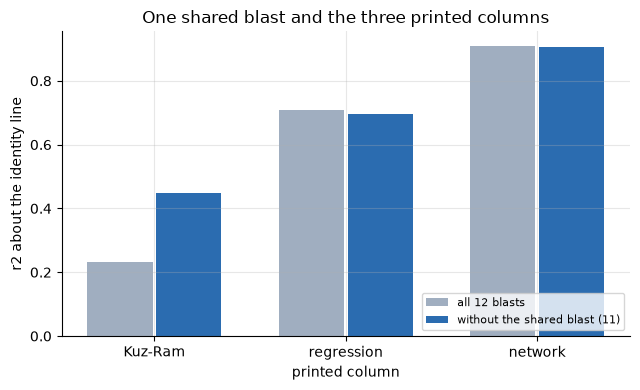

In [9]:
# Variance explained with all 12 blasts and with the 11 that are not training rows, for each printed column
labels = [label.split(" (")[0] for label in effect]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(positions - 0.18, [v[0] for v in effect.values()], width=0.34, color="#a0aec0", label="all 12 blasts")
ax.bar(positions + 0.18, [v[1] for v in effect.values()], width=0.34, color="#2b6cb0",
       label="without the shared blast (11)")
ax.set_xticks(positions, labels)
ax.set_ylabel("r2 about the identity line")
ax.set_xlabel("printed column")
ax.set_title("One shared blast and the three printed columns")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Grey bars are the variance explained on all 12 blasts and blue bars on the 11 that are not training rows, for each printed column. The classical pair is the only one that changes visibly, with the blue bar well above the grey one, while the regression and network pairs are nearly identical. The picture shows that the effect of one row depends on the predictor: a column that misses badly on that row gains a lot when the row leaves, and a column that already predicts it well barely moves. It does not give a correct score for the classical column, only a second one that depends on a choice.

## Results

**Answer:** On their own 12-blast table the published predictors score, on the variance explained about the identity line, 0.2318 for the Kuz-Ram column, 0.7082 for the regression and 0.9096 for the network, against -0.0093 for a constant, and the same Kuz-Ram column has a Pearson r2 of 0.5698: a table that reported only the correlation would rank the classical column higher than it deserves. The intervals are wide (-1.811 to 0.857, -0.022 to 0.874 and 0.648 to 0.974), so only the network is clearly better than a constant. Recomputed from its equations, the published regression explains 0.8537 and 0.8272 of the variance on the two sets, 0.1070 and 0.1190 more than the printed tables; the engine's classical predictor reproduces the printed Kuz-Ram column to 0.003 m; and removing the one blast that is also a training row lifts the classical score from 0.2318 to 0.4478.

**What follows.** A published score on 12 blasts is a weak basis for ranking predictors, and the ranking can change with one row. The printed table and the printed equations of the same paper disagree, so anyone reproducing the regression should apply the equations and not copy the table.

**What this notebook does not show.** All of this is on 12 or 13 blasts from sites that are also in the training table, so none of it says how a predictor behaves at a mine it has not seen. The agreement of the classical column and the engine is partly circular, because the factors were recovered from that column. And the notebook cannot say which of the printed table and the printed equations is wrong. How the predictors do when whole campaigns are held out is the question of topic 04.

## Summary

- A printed prediction column can be scored like any other prediction, and two statistics that share a name give different answers on the same column (0.5698 against 0.2318 for Kuz-Ram).
- On 12 blasts every score has a wide interval, and only the network is clearly better than a constant.
- The published regression, applied from its equations, explains 0.1070 and 0.1190 more variance than the tables printed for it, though the intervals overlap.
- The engine's classical predictor matches the printed Kuz-Ram column to 0.003 m because its rock factors were recovered from that column.
- One blast that is also a training row moves the classical score from 0.2318 to 0.4478.
- Next: notebook 04 asks how much of the classical score survives when the site is not known in advance (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the regression, the discriminant, the 13-blast validation set)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the network and the 12-blast validation set)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (the classical equation as reprinted)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/